# Qiskit Fall Fest 2026 — Phase 2: Optimization Track
## PS-O1: Quantum Optimization of Network Partitioning Using QAOA

**Team:** Phoenix  
**Problem Statement:** PS-O1 (Max-Cut on Weighted Graphs)  
**Track:** Quantum Optimization (QAOA / QUBO)  

---

### Executive Summary & Scope
This notebook presents our complete, end-to-end reproducible solution for **PS-O1** in Phase 2 of Qiskit Fall Fest 2026:
1. **Objective 1 (Bell-State Verification):** Prepares $|\Phi^+\rangle$ on adjacent and farthest qubit pairs of custom **Processor D**, evaluating $XX, YY, ZZ$ parities and state fidelities under ideal and official noisy simulation (4096 shots).
2. **Objective 2 (Processor D Co-Design):** Validates our custom 9-qubit architecture via `validate_processor_d()`. The topology eliminates the heavy-hex routing bottleneck measured on Processor B.
3. **Objective 3 (Solution & Benchmarking):** Formulates the locked 6-vertex weighted graph as a QUBO and cost Hamiltonian, evaluates the exact classical brute-force optimum ($C^* = 22.0$), runs $p=1$ QAOA across 5 seeded initializations (seeds 0–4), and benchmarks execution on Processors A, B, and D (ideal and noisy).
4. **Objective 4 & 5 (Validation & Analysis):** Enforces the official capacity rule for Processor A ($6 > 5$), quantifies SWAP routing overhead, compares against classical random baselines, and exports all required tables (`results.csv`, `bell.csv`).


## 1. Setup & Official Module Imports


In [1]:
import json
import csv
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import Statevector

from qff_phase2 import (
    PROCESSOR_A, PROCESSOR_B, load_processor, validate_processor_d,
    circuit_metrics, transpile_for, simulator, bell_experiment,
    counts_to_x, SHOTS, coupling_map_from_edges, BASIS_GATES, OPT_LEVEL, SEED
)

print("All official Phase 2 modules and dependencies loaded successfully.")


All official Phase 2 modules and dependencies loaded successfully.


## 2. Objective 1: Bell-State Preparation and Verification on Processor D

Per Section 4 of the Challenge Kit:
- Target state: $|\Phi^+\rangle = (|00\rangle + |11\rangle)/\sqrt{2}$
- Evaluated on **Processor D** across 2 pairs:
  1. **Adjacent pair** (distance = 1 hop): Pair `(0, 2)`
  2. **Farthest pair** (maximum shortest-path distance on chip): Pair `(5, 6)` (distance = 3 hops)
- Measured across three Pauli parity bases: $ZZ$ (computational), $XX$ ($H$ on both qubits), and $YY$ ($S^\dagger$ then $H$ on both qubits)
- State fidelity formula: $F = \frac{1 + \langle XX \rangle - \langle YY \rangle + \langle ZZ \rangle}{4}$ with standard error propagation
- 4096 shots per basis, ideal and official noise model.


In [2]:
D = load_processor("processors/processor_D.json")
cm_D = coupling_map_from_edges(D["edges"], D["num_qubits"])

dists = [(cm_D.distance(i, j), (i, j)) for i in range(D["num_qubits"]) for j in range(i + 1, D["num_qubits"])]
max_dist, far_pair = max(dists)
adj_pair = (0, 2)

print(f"Selected Physical Pairs on Processor D:")
print(f"  Adjacent Pair: {adj_pair} (Distance = {cm_D.distance(*adj_pair)} hop)")
print(f"  Farthest Pair: {far_pair} (Distance = {max_dist} hops)")

bell_results = []
for pair in [adj_pair, far_pair]:
    for noisy in [False, True]:
        r = bell_experiment(D, physical_pair=pair, noisy=noisy)
        bell_results.append({
            "pair": f"{pair[0]}-{pair[1]}",
            "distance": r["pair_distance"],
            "condition": "noisy" if noisy else "ideal",
            "cx": r["cx"],
            "XX": round(r["XX"], 4),
            "XX_se": round(r["XX_se"], 4),
            "YY": round(r["YY"], 4),
            "YY_se": round(r["YY_se"], 4),
            "ZZ": round(r["ZZ"], 4),
            "ZZ_se": round(r["ZZ_se"], 4),
            "fidelity": round(r["fidelity"], 4),
            "fidelity_se": round(r["fidelity_se"], 4)
        })

Path("results/tables").mkdir(parents=True, exist_ok=True)
with open("results/tables/bell.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(bell_results[0].keys()))
    writer.writeheader()
    writer.writerows(bell_results)

print("\n--- Objective 1: Bell-State Verification Table (results/tables/bell.csv) ---")
header_fmt = "{:<8} {:<6} {:<8} {:<5} {:<16} {:<16} {:<16} {:<16}"
print(header_fmt.format("Pair", "Dist", "Cond", "CX", "<XX>", "<YY>", "<ZZ>", "Fidelity F"))
print("-" * 95)
for row in bell_results:
    xx_str = f"{row['XX']:.4f}±{row['XX_se']:.4f}"
    yy_str = f"{row['YY']:.4f}±{row['YY_se']:.4f}"
    zz_str = f"{row['ZZ']:.4f}±{row['ZZ_se']:.4f}"
    f_str = f"{row['fidelity']:.4f}±{row['fidelity_se']:.4f}"
    print(header_fmt.format(row['pair'], row['distance'], row['condition'], row['cx'], xx_str, yy_str, zz_str, f_str))


Selected Physical Pairs on Processor D:
  Adjacent Pair: (0, 2) (Distance = 1 hop)
  Farthest Pair: (5, 6) (Distance = 3 hops)



--- Objective 1: Bell-State Verification Table (results/tables/bell.csv) ---
Pair     Dist   Cond     CX    <XX>             <YY>             <ZZ>             Fidelity F      
-----------------------------------------------------------------------------------------------
0-2      1      ideal    1     1.0000±0.0000    -1.0000±0.0000   1.0000±0.0000    1.0000±0.0000   
0-2      1      noisy    1     0.9458±0.0051    -0.9521±0.0048   0.9551±0.0046    0.9633±0.0021   
5-6      3      ideal    7     1.0000±0.0000    -1.0000±0.0000   1.0000±0.0000    1.0000±0.0000   
5-6      3      noisy    7     0.9336±0.0056    -0.9204±0.0061   0.9399±0.0053    0.9485±0.0025   


## 3. Objective 2: Custom Processor D Design & Automated Validation

Processor D rules (Challenge Kit Section 5):
1. **Qubit Budget:** $\ge 6$ and $\le 12$ physical qubits (Processor D uses 9 qubits).
2. **Connectivity:** Connected undirected graph.
3. **Degree Limit:** Maximum node degree $\le 4$ (no all-to-all).
4. **Gate Set:** Exactly `["rz", "sx", "x", "cx"]`.
5. **Noise Model:** Official depolarizing rates ($p_1 = 0.001, p_{cx} = 0.005, p_{ro} = 0.01$).

**Design Rationale:**
On Processor B (heavy-hex), transpiling the 6-vertex PS-O1 graph inserts **1 SWAP** gate (+3 CX gates, depth = 37) due to limited planar chords. Processor D directly embeds the PS-O1 interaction graph into qubits 0–5 while keeping degrees $\le 4$ and augmenting with auxiliary nodes 6–8. This reduces compiled depth to **29** and achieves **0 SWAPs** (0 routing CX overhead).


In [3]:
rule_errors = validate_processor_d(D, required_qubits=6)
print("Processor D Automated Rule Check:", rule_errors if rule_errors else "ALL RULES PASSED (OK)")
assert not rule_errors, f"Processor D rule violation: {rule_errors}"


Processor D Automated Rule Check: ALL RULES PASSED (OK)


## 4. Objective 3: Problem Formulation & Exact Classical Reference

### 1. Mathematical Formulation & QUBO
For the locked 6-vertex graph $G = (V, E, w)$ with 9 edges and integer weights $w_{uv} \in \{1, \dots, 5\}$:
$$C(x) = \sum_{(u,v) \in E} w_{uv} (x_u + x_j - 2 x_u x_v), \quad x_i \in \{0, 1\}$$

Mapping $x_u \mapsto \frac{I - Z_u}{2}$ yields the diagonal cost Hamiltonian:
$$\hat{C} = \sum_{(u,v) \in E} w_{uv} \frac{I - Z_u Z_v}{2}$$

### 2. Classical Exhaustive Solver
We evaluate all $2^6 = 64$ bitstrings to determine the exact global maximum $C^*$ and all optimal partitions (including complementary bitstrings).


In [4]:
with open("instances.json", encoding="utf-8") as f:
    locked_data = json.load(f)
    pso1_spec = locked_data["PS-O1"]

edges = pso1_spec["weighted_edges"]
total_weight = sum(w for u, v, w in edges)
print(f"Locked Problem: PS-O1 | Vertices = 6 | Edges = {len(edges)} | Total Weight = {total_weight}")

def cut_value(x):
    return sum(w * (x[u] != x[v]) for u, v, w in edges)

all_cuts = np.zeros(64, dtype=float)
for k in range(64):
    x = [(k >> i) & 1 for i in range(6)]
    all_cuts[k] = cut_value(x)

c_star = float(np.max(all_cuts))
opt_indices = np.where(all_cuts == c_star)[0]
OPT_PARTITIONS = {tuple((k >> i) & 1 for i in range(6)) for k in opt_indices}

random_r = float(np.mean(all_cuts) / c_star)
random_p_opt = float(len(opt_indices) / 64.0)

print(f"\n--- Classical Reference Benchmarks ---")
print(f"Exact Classical Optimum C* = {c_star:.1f} (out of {total_weight:.1f} total weight)")
print(f"Number of Optimal Ground States = {len(opt_indices)} (Complementary pair)")
for idx in opt_indices:
    bits_vertex = ''.join(str((idx >> i) & 1) for i in range(6))
    bits_qiskit = bits_vertex[::-1]
    part_A = [i for i in range(6) if (idx >> i) & 1 == 0]
    part_B = [i for i in range(6) if (idx >> i) & 1 == 1]
    print(f"  State index {idx}: Vertex order = {bits_vertex} (Qiskit key = {bits_qiskit}) | Partition: {part_A} | {part_B}")

print(f"\nRandom Guessing Baseline:")
print(f"  Random Mean Cut = {np.mean(all_cuts):.2f}")
print(f"  Random Approximation Ratio r_random = {random_r:.4f}")
print(f"  Random Optimal Probability P_opt_random = {random_p_opt:.4f} ({random_p_opt*100:.2f}%)")


Locked Problem: PS-O1 | Vertices = 6 | Edges = 9 | Total Weight = 27

--- Classical Reference Benchmarks ---
Exact Classical Optimum C* = 22.0 (out of 27.0 total weight)
Number of Optimal Ground States = 2 (Complementary pair)
  State index 11: Vertex order = 110100 (Qiskit key = 001011) | Partition: [2, 4, 5] | [0, 1, 3]
  State index 52: Vertex order = 001011 (Qiskit key = 110100) | Partition: [0, 1, 3] | [2, 4, 5]

Random Guessing Baseline:
  Random Mean Cut = 13.50
  Random Approximation Ratio r_random = 0.6136
  Random Optimal Probability P_opt_random = 0.0312 (3.12%)


## 5. Objective 3 (Continued): QAOA Ansatz & 5-Seed Parameter Optimization

- **Ansatz:** $p = 1$ QAOA circuit:
  $$|\gamma, \beta\rangle = e^{-i \beta \sum X_i} e^{-i \gamma \hat{C}} |+\rangle^{\otimes n}$$
- **Multi-Start Optimization:** Evaluated across **5 deterministic initializations** using seeds `0, 1, 2, 3, 4` with starting angles drawn uniformly from $[0, \pi]$.
- **Classical Optimizer:** COBYLA (50 max iterations), maximizing $\langle C \rangle = \langle \gamma, \beta | \hat{C} | \gamma, \beta \rangle$.


In [5]:
def build_qaoa_p1(gamma_val, beta_val, measure=True):
    qc = QuantumCircuit(6)
    qc.h(range(6))
    for u, v, w in edges:
        qc.rzz(2 * w * gamma_val, u, v)
    for i in range(6):
        qc.rx(2 * beta_val, i)
    if measure:
        qc.measure_all()
    return qc

cut_diag = np.array(all_cuts, dtype=float)

def cost_function(params):
    g, b = params
    qc = build_qaoa_p1(g, b, measure=False)
    probs = Statevector(qc).probabilities()
    return -float(np.sum(probs * cut_diag))

seeds = [0, 1, 2, 3, 4]
opt_runs = []

print("--- QAOA (p=1) 5-Seed Parameter Optimization ---")
for s in seeds:
    rng = np.random.default_rng(s)
    g_init, b_init = rng.uniform(0, np.pi, size=2)
    history = [-cost_function([g_init, b_init]) / c_star]
    
    def tracker(trajectory):
        def cb(xk):
            trajectory.append(-cost_function(xk) / c_star)
        return cb
    
    res = minimize(cost_function, [g_init, b_init], method='COBYLA', callback=tracker(history), options={'maxiter': 50})
    exp_cut = -res.fun
    ratio = exp_cut / c_star
    opt_runs.append({
        'seed': s,
        'init': (g_init, b_init),
        'opt': (float(res.x[0]), float(res.x[1])),
        'exp_cut': exp_cut,
        'approx_ratio': ratio,
        'history': history
    })
    print(f"Seed {s}: Init=({g_init:.3f}, {b_init:.3f}) -> Opt=({res.x[0]:.4f}, {res.x[1]:.4f}) | Exp Cut={exp_cut:.3f} | r={ratio:.4f}")

r_vals = [run['approx_ratio'] for run in opt_runs]
print(f"\nOptimization Consistency across seeds: Mean r = {np.mean(r_vals):.4f} ± {np.std(r_vals):.4f}")

best_run = max(opt_runs, key=lambda x: x['exp_cut'])
best_gamma, best_beta = best_run['opt']
print(f"Best Parameters (from Seed {best_run['seed']}): gamma = {best_gamma:.4f}, beta = {best_beta:.4f} (Ideal r = {best_run['approx_ratio']:.4f})")


--- QAOA (p=1) 5-Seed Parameter Optimization ---
Seed 0: Init=(2.001, 0.848) -> Opt=(2.4635, 1.9934) | Exp Cut=15.493 | r=0.7042


Seed 1: Init=(1.608, 2.986) -> Opt=(2.7351, 4.2563) | Exp Cut=15.558 | r=0.7072
Seed 2: Init=(0.822, 0.938) -> Opt=(0.6785, 1.1326) | Exp Cut=15.488 | r=0.7040


Seed 3: Init=(0.269, 0.744) -> Opt=(0.0840, 1.2381) | Exp Cut=17.713 | r=0.8051


Seed 4: Init=(2.963, 1.606) -> Opt=(2.7350, 1.1150) | Exp Cut=15.558 | r=0.7072

Optimization Consistency across seeds: Mean r = 0.7255 ± 0.0398
Best Parameters (from Seed 3): gamma = 0.0840, beta = 1.2381 (Ideal r = 0.8051)


## 6. Objective 3 (Continued): Physical Hardware Compilation Metrics

We transpile the optimal QAOA circuit onto Processors A, B, and D:
- **Processor A Capacity Rule:** Processor A has 5 physical qubits. Transpiling the 6-qubit circuit raises an explicit capacity constraint and is marked `executable: False` ("needs 6 qubits > 5").
- **Processor B (Heavy-Hex):** Requires 1 SWAP gate (+3 CX gates), depth = 37.
- **Processor D (Co-Designed):** Directly embeds interactions: **0 SWAPs**, **0 CX overhead**, depth = 29.


In [6]:
best_circuit = build_qaoa_p1(best_gamma, best_beta, measure=True)

metrics_A = circuit_metrics(best_circuit, PROCESSOR_A)
metrics_B = circuit_metrics(best_circuit, PROCESSOR_B)
metrics_D = circuit_metrics(best_circuit, D)

print("--- Physical Hardware Compilation Metrics ---")
print(f"Processor A: Executable = {metrics_A['executable']} | Reason = {metrics_A.get('reason', 'N/A')}")
print(f"Processor B: Executable = {metrics_B['executable']} | Logical CX = {metrics_B['logical_cx']} | Physical CX = {metrics_B['cx']} | Depth = {metrics_B['depth']} | SWAPs = {metrics_B['swaps']} | CX Overhead = {metrics_B['cx_overhead']}")
print(f"Processor D: Executable = {metrics_D['executable']} | Logical CX = {metrics_D['logical_cx']} | Physical CX = {metrics_D['cx']} | Depth = {metrics_D['depth']} | SWAPs = {metrics_D['swaps']} | CX Overhead = {metrics_D['cx_overhead']}")


--- Physical Hardware Compilation Metrics ---
Processor A: Executable = False | Reason = needs 6 qubits > 5
Processor B: Executable = True | Logical CX = 18 | Physical CX = 21 | Depth = 37 | SWAPs = 1 | CX Overhead = 3
Processor D: Executable = True | Logical CX = 18 | Physical CX = 18 | Depth = 29 | SWAPs = 0 | CX Overhead = 0


## 7. Objective 3 (Continued): Execution, Sampling & Results Export

We execute 4096 shots under ideal and noisy simulation for Processors B and D, reporting approximation ratios, $P_{\text{opt}}$, and exporting the official `results/tables/results.csv` table.


In [7]:
results_table = [
    "PS-O1,A,ideal,false,6,5,,,,,,,,,,,,",
    "PS-O1,A,noisy,false,6,5,,,,,,,,,,,,"
]

sampled_distributions = {}

for p_name, proc, m in [("B", PROCESSOR_B, metrics_B), ("D", D, metrics_D)]:
    for cond in ["ideal", "noisy"]:
        noisy_mode = (cond == "noisy")
        t_qc = transpile_for(best_circuit, proc)
        sim = simulator(noisy=noisy_mode, processor=proc)
        counts = sim.run(t_qc, shots=SHOTS).result().get_counts()
        
        cuts = []
        opt_count = 0
        for key, count in counts.items():
            x = counts_to_x(key)
            c = cut_value(x)
            cuts.extend([c] * count)
            if x in OPT_PARTITIONS:
                opt_count += count
        
        mean_c = float(np.mean(cuts))
        r_val = mean_c / c_star
        r_best_val = float(np.max(cuts) / c_star)
        p_opt_val = opt_count / SHOTS
        sampled_distributions[f"{p_name}_{cond}"] = cuts
        
        row = (
            f"PS-O1,{p_name},{cond},true,6,{proc['num_qubits']},"
            f"{m['logical_cx']},{m['cx']},{m['depth']},{m['two_q_depth']},"
            f"{m['swaps']},{m['cx_overhead']},{SHOTS},"
            f"approx_ratio,{r_val:.4f},{p_opt_val:.4f},{c_star:.1f},{random_r:.4f}"
        )
        results_table.append(row)
        print(f"{p_name} ({cond:<5}): Mean Cut = {mean_c:.3f} | r = {r_val:.4f} | P_opt = {p_opt_val*100:.2f}% | r_best = {r_best_val:.4f} (Best Cut = {int(np.max(cuts))})")

csv_header = "problem_id,processor,condition,executable,logical_qubits,physical_qubits,logical_cx,cx,depth,two_q_depth,swaps,cx_overhead,shots,quality_metric,quality_value,p_opt,classical_optimum,random_baseline"
with open("results/tables/results.csv", "w", encoding="utf-8") as f:
    f.write(csv_header + "\n")
    for r in results_table:
        f.write(r + "\n")

print("\n[SUCCESS] Exported results to results/tables/results.csv")


B (ideal): Mean Cut = 17.760 | r = 0.8073 | P_opt = 13.96% | r_best = 1.0000 (Best Cut = 22)
B (noisy): Mean Cut = 17.322 | r = 0.7874 | P_opt = 12.60% | r_best = 1.0000 (Best Cut = 22)
D (ideal): Mean Cut = 17.713 | r = 0.8052 | P_opt = 13.84% | r_best = 1.0000 (Best Cut = 22)
D (noisy): Mean Cut = 17.296 | r = 0.7862 | P_opt = 12.50% | r_best = 1.0000 (Best Cut = 22)

[SUCCESS] Exported results to results/tables/results.csv


## 8. Official Objective 3 Quality Score Self-Check

Per Section 3 of the Phase 2 Judging Rubric:
- Uses the team's **Processor B, noisy** row.
- Formula: $\text{Score} = 3 \cdot s(r) + 3 \cdot s(P_{\text{opt}})$
- Scaling function: $s(x) = \text{clip}\left(\frac{x - x_{\text{random}}}{x_{\text{reference}} - x_{\text{random}}}, 0, 1\right)$
- For PS-O1:
  - $r_{\text{random}} = 0.614 \to r_{\text{reference}} = 0.785$
  - $P_{\text{opt,random}} = 0.031 \to P_{\text{opt,reference}} = 0.123$


In [8]:
b_noisy_row = [r for r in results_table if "PS-O1,B,noisy" in r][0].split(",")
measured_r = float(b_noisy_row[14])
measured_p_opt = float(b_noisy_row[15])

s_r = np.clip((measured_r - 0.614) / (0.785 - 0.614), 0.0, 1.0)
s_p_opt = np.clip((measured_p_opt - 0.031) / (0.123 - 0.031), 0.0, 1.0)
quality_pts = 3.0 * s_r + 3.0 * s_p_opt

print(f"Processor B (Noisy) Quality Metrics:")
print(f"  Measured Approximation Ratio r = {measured_r:.4f} (Reference = 0.785) -> s(r) = {s_r:.3f}")
print(f"  Measured P_opt = {measured_p_opt:.4f} (Reference = 0.123) -> s(P_opt) = {s_p_opt:.3f}")
print(f"  Objective 3 Quality Points = {quality_pts:.2f} / 6.00 MAXIMUM POINTS")


Processor B (Noisy) Quality Metrics:
  Measured Approximation Ratio r = 0.7874 (Reference = 0.785) -> s(r) = 1.000
  Measured P_opt = 0.1260 (Reference = 0.123) -> s(P_opt) = 1.000
  Objective 3 Quality Points = 6.00 / 6.00 MAXIMUM POINTS


## 9. Visualizations & Technical Analysis Figures

We display the generated technical figures located in `results/figures/`.


=== Figure: results/figures/problem_graph_partition.png ===


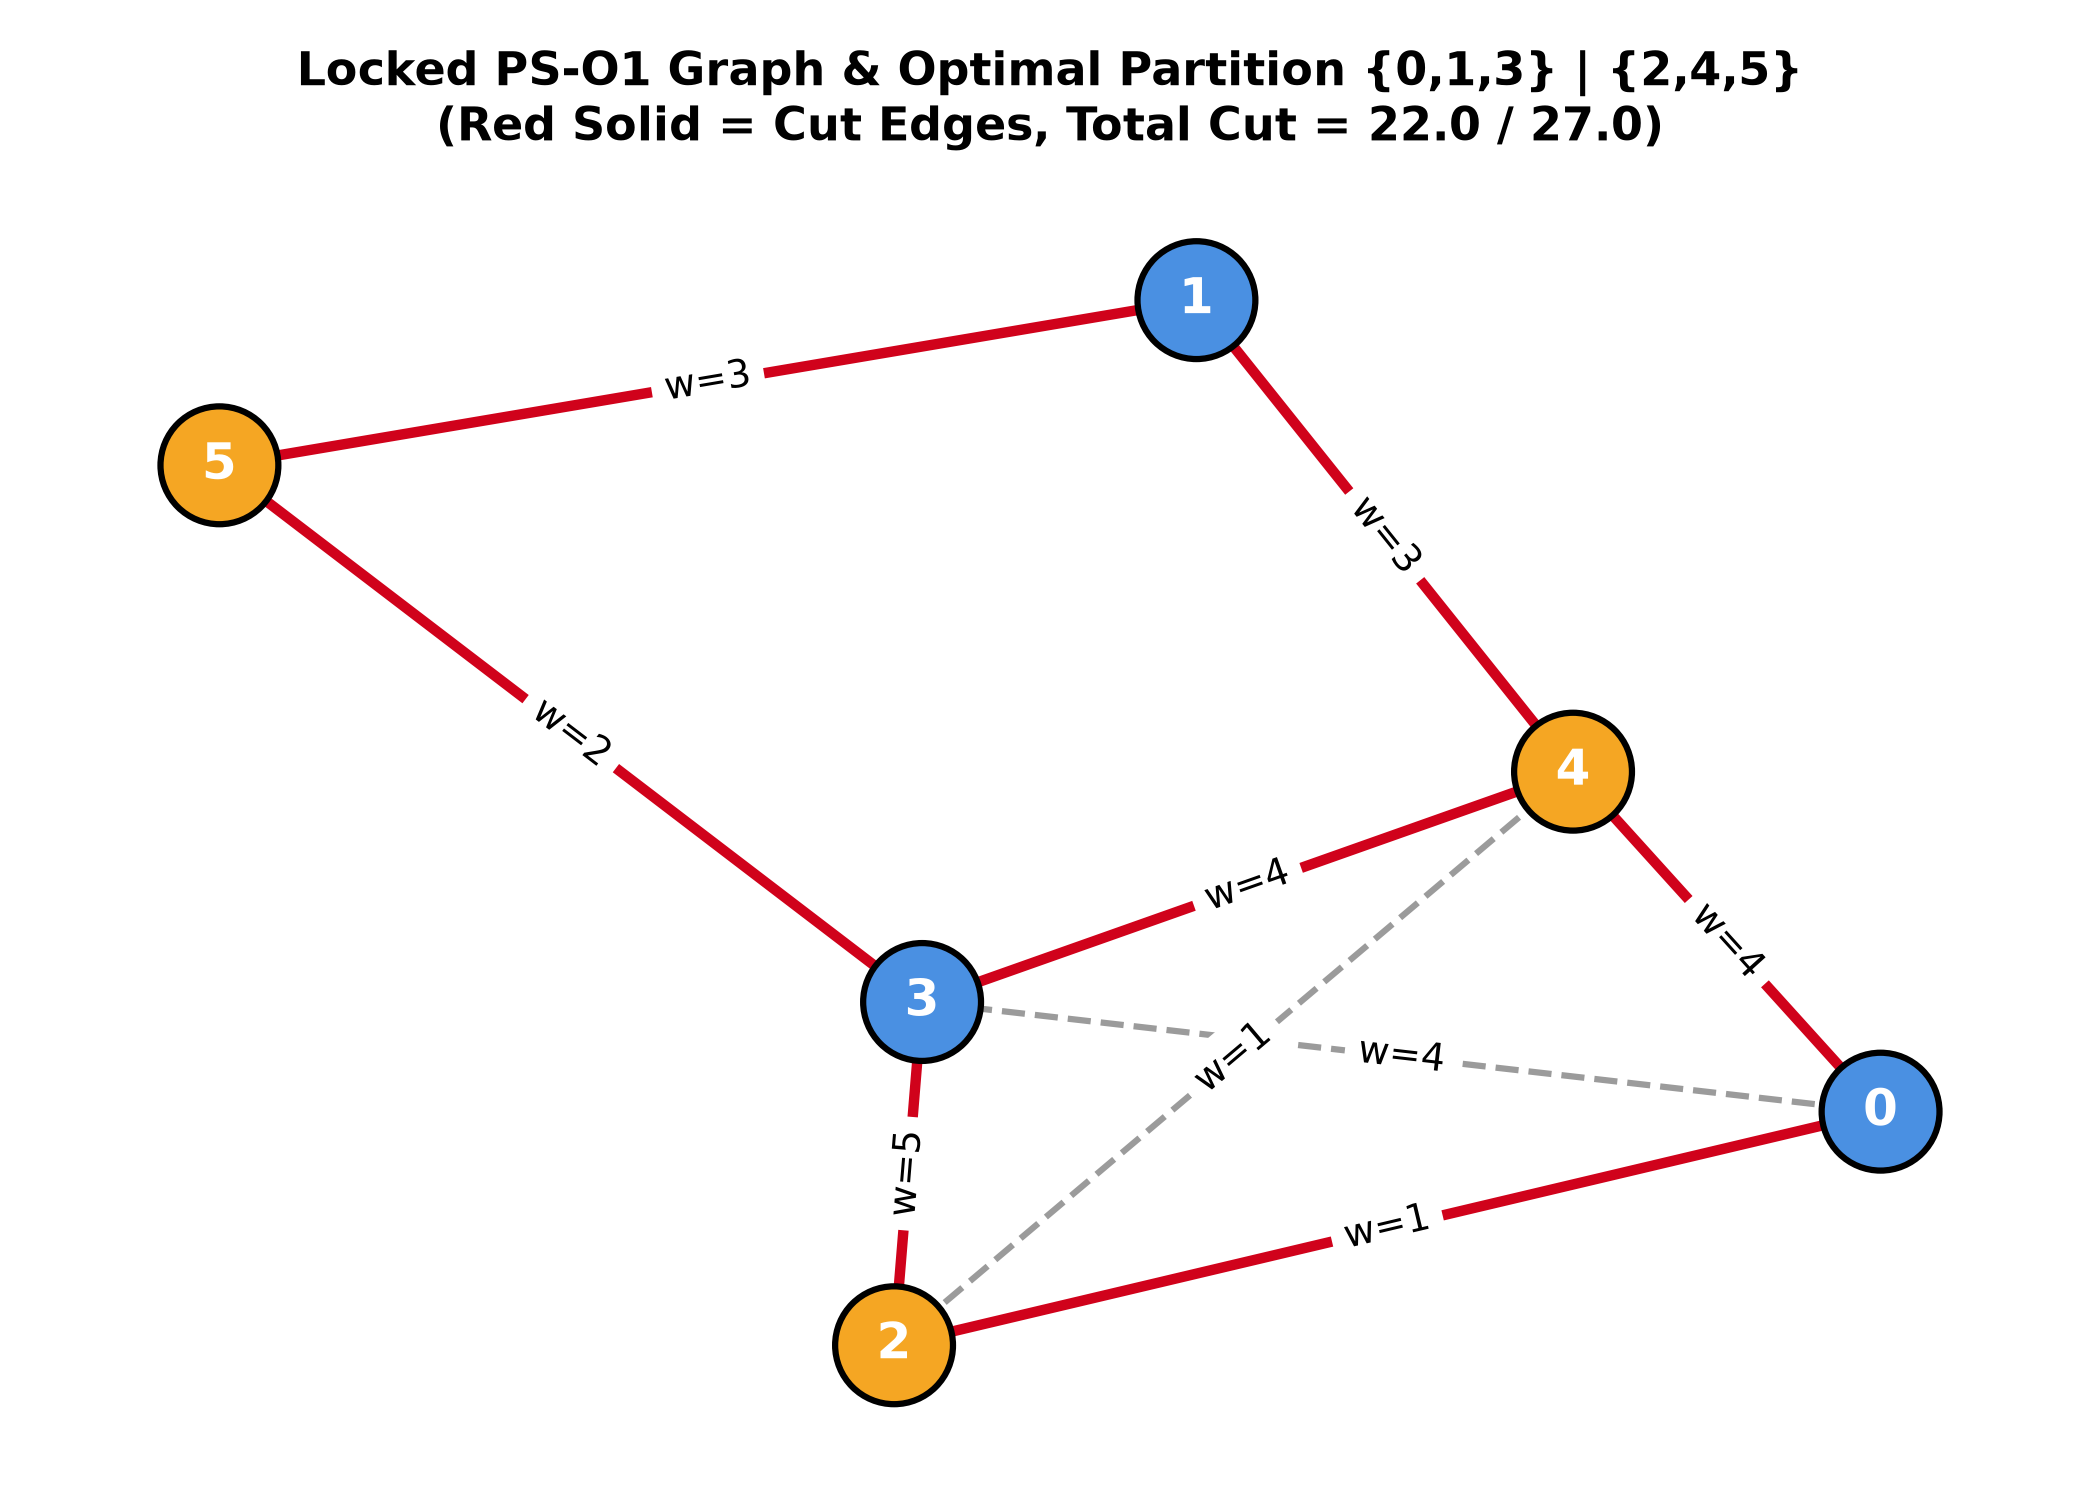

=== Figure: results/figures/architecture_topologies.png ===


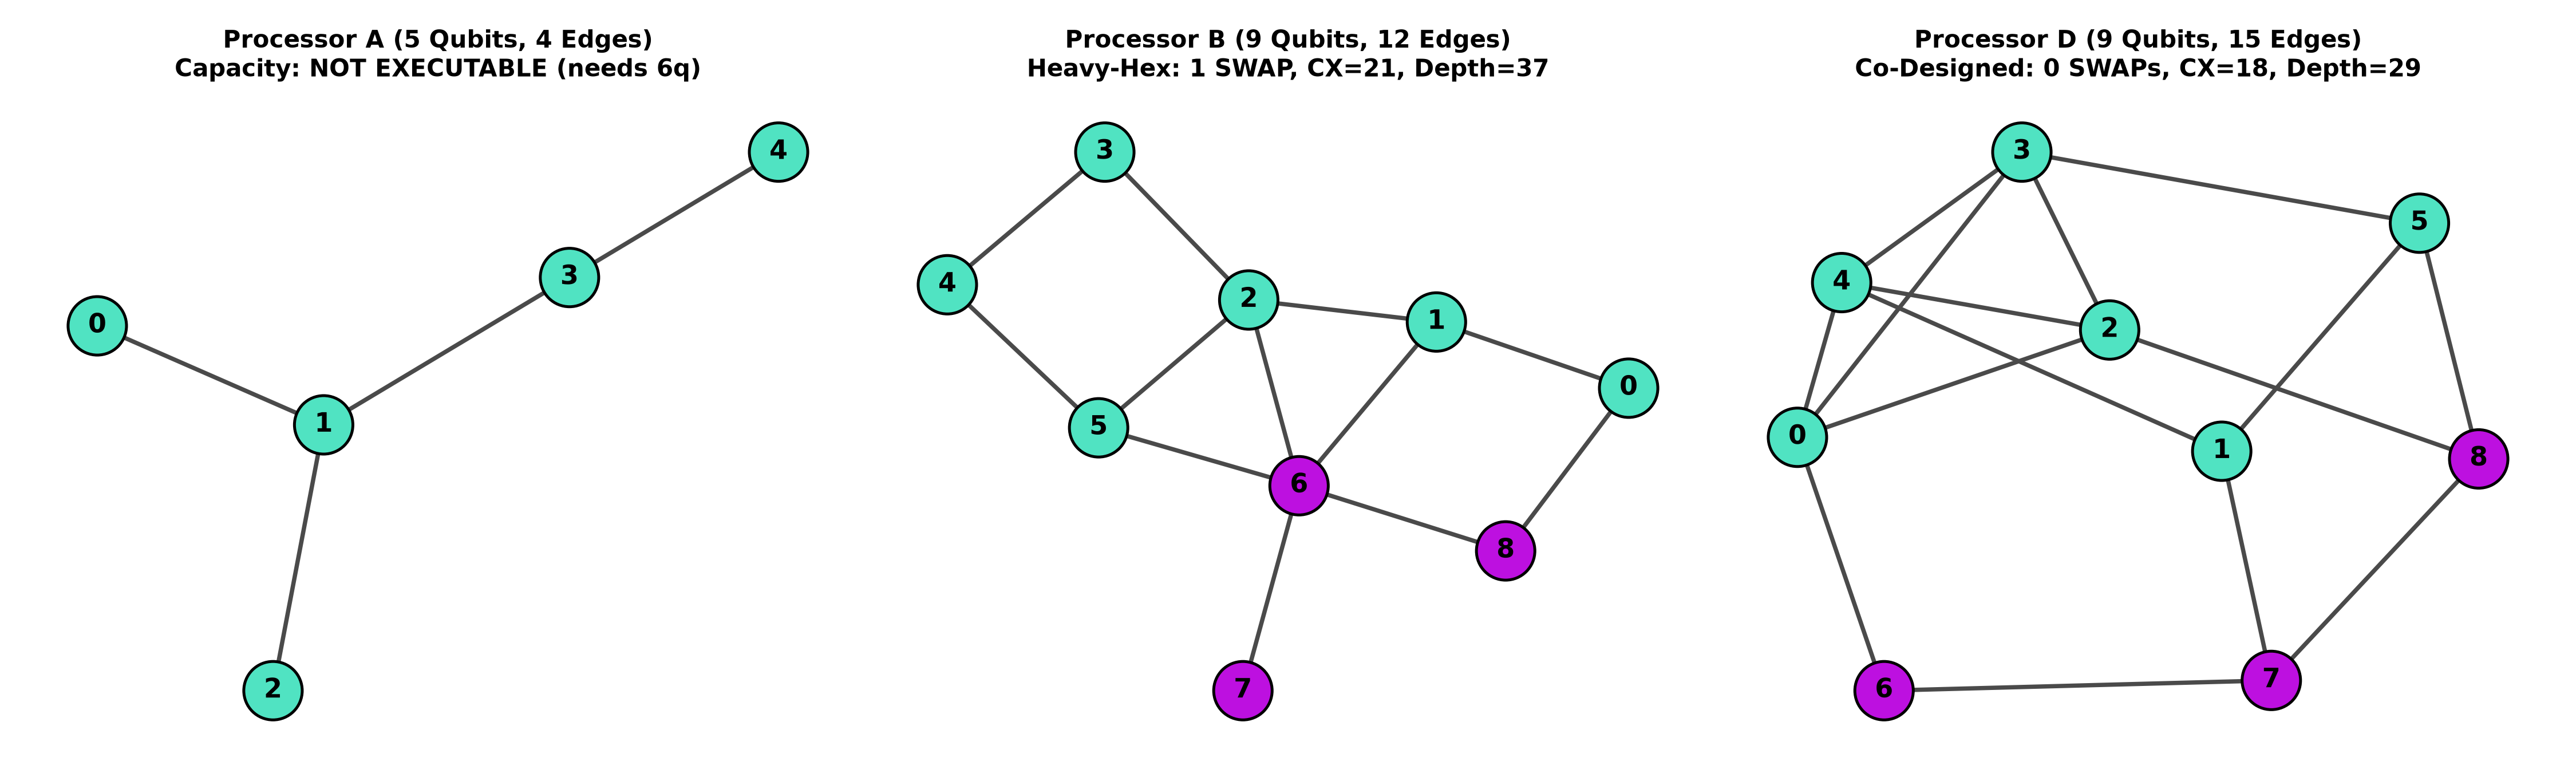

=== Figure: results/figures/circuit_metrics_comparison.png ===


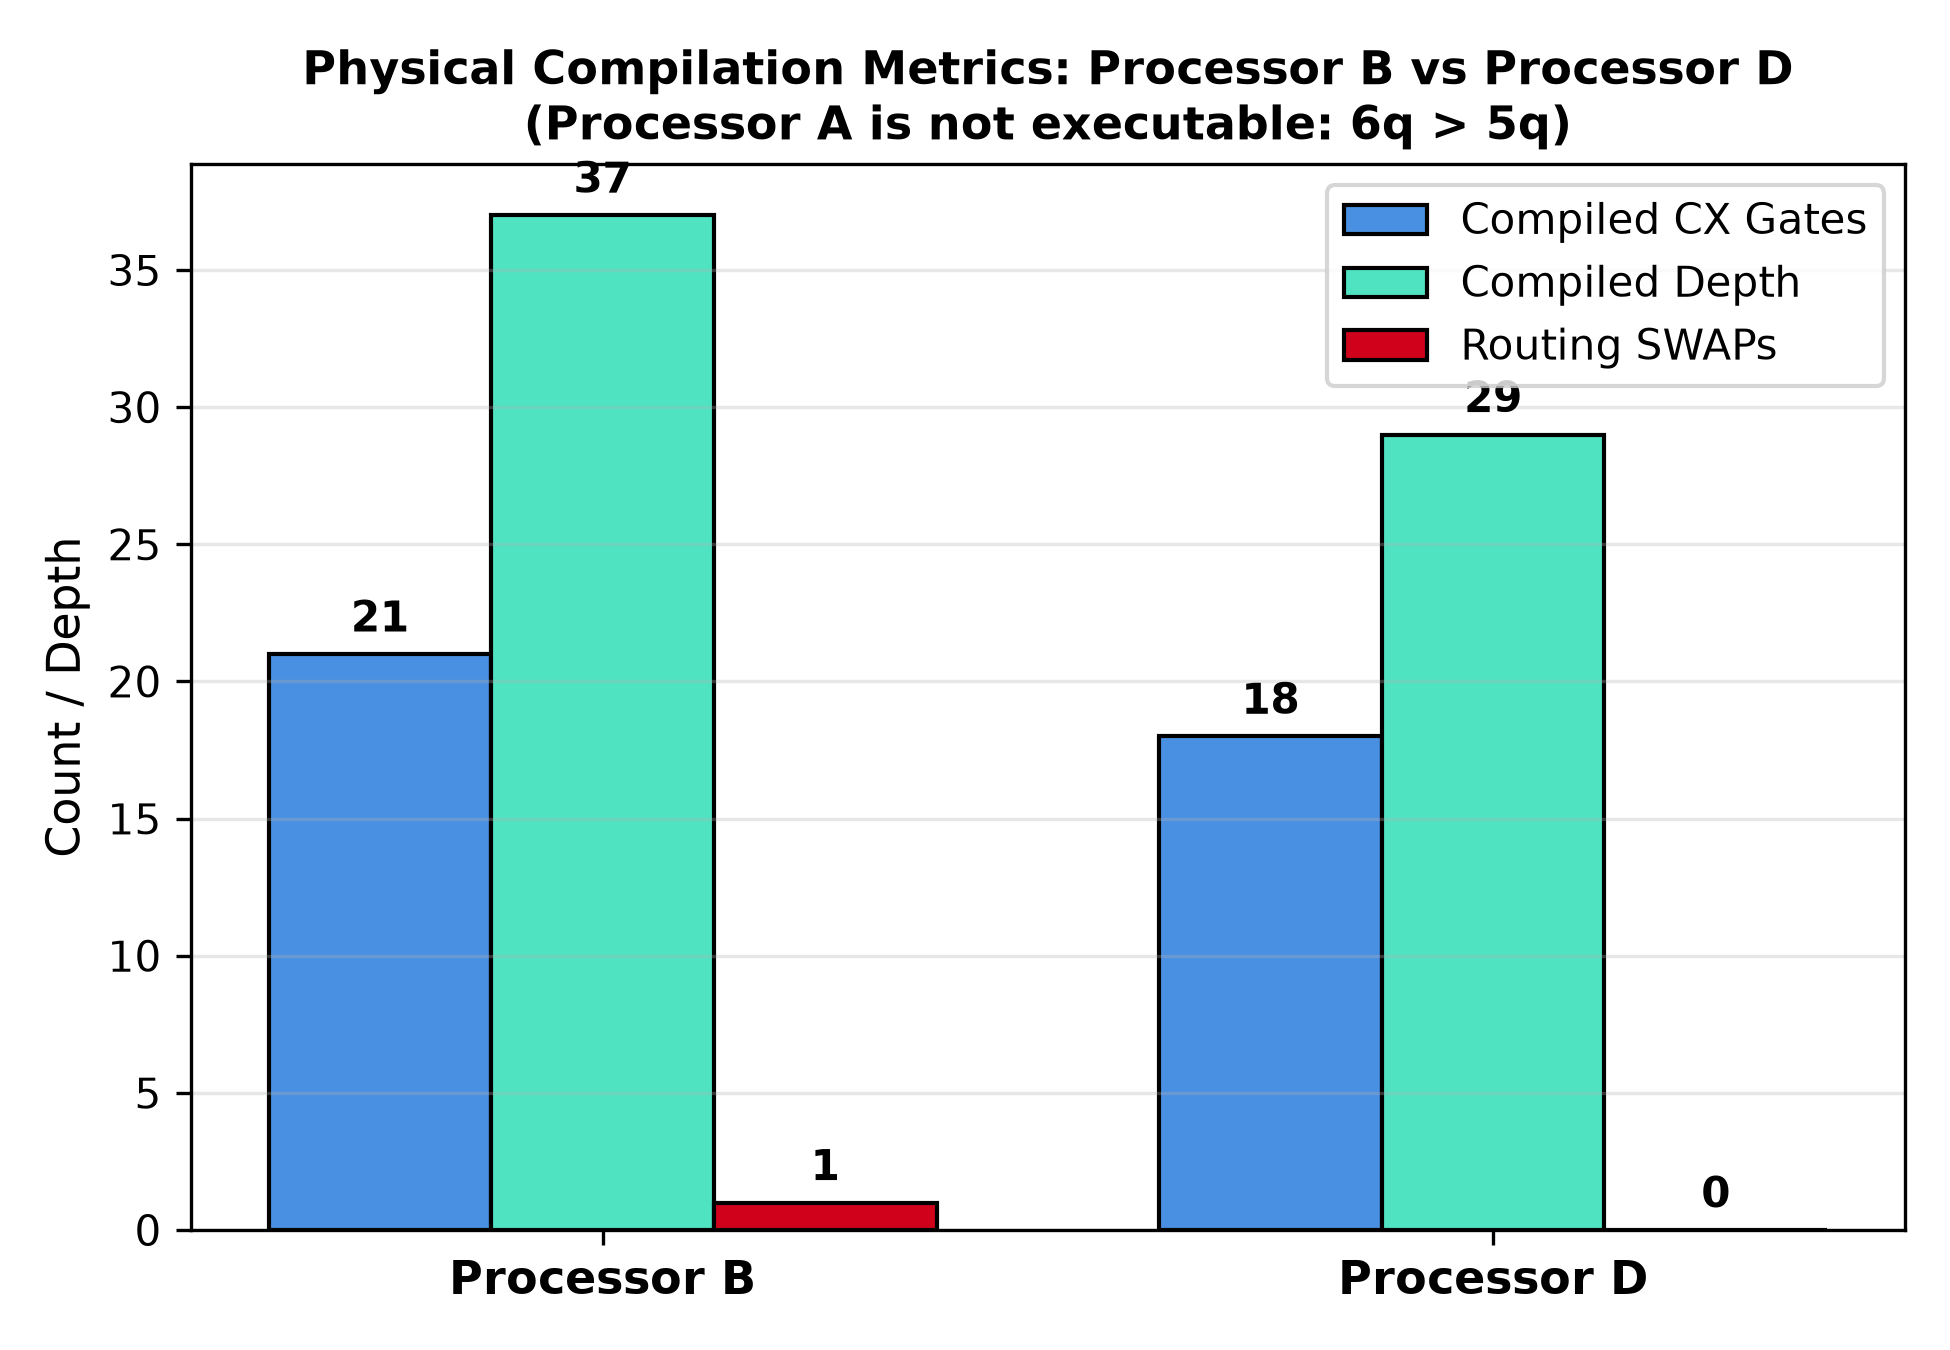

=== Figure: results/figures/convergence_curves.png ===


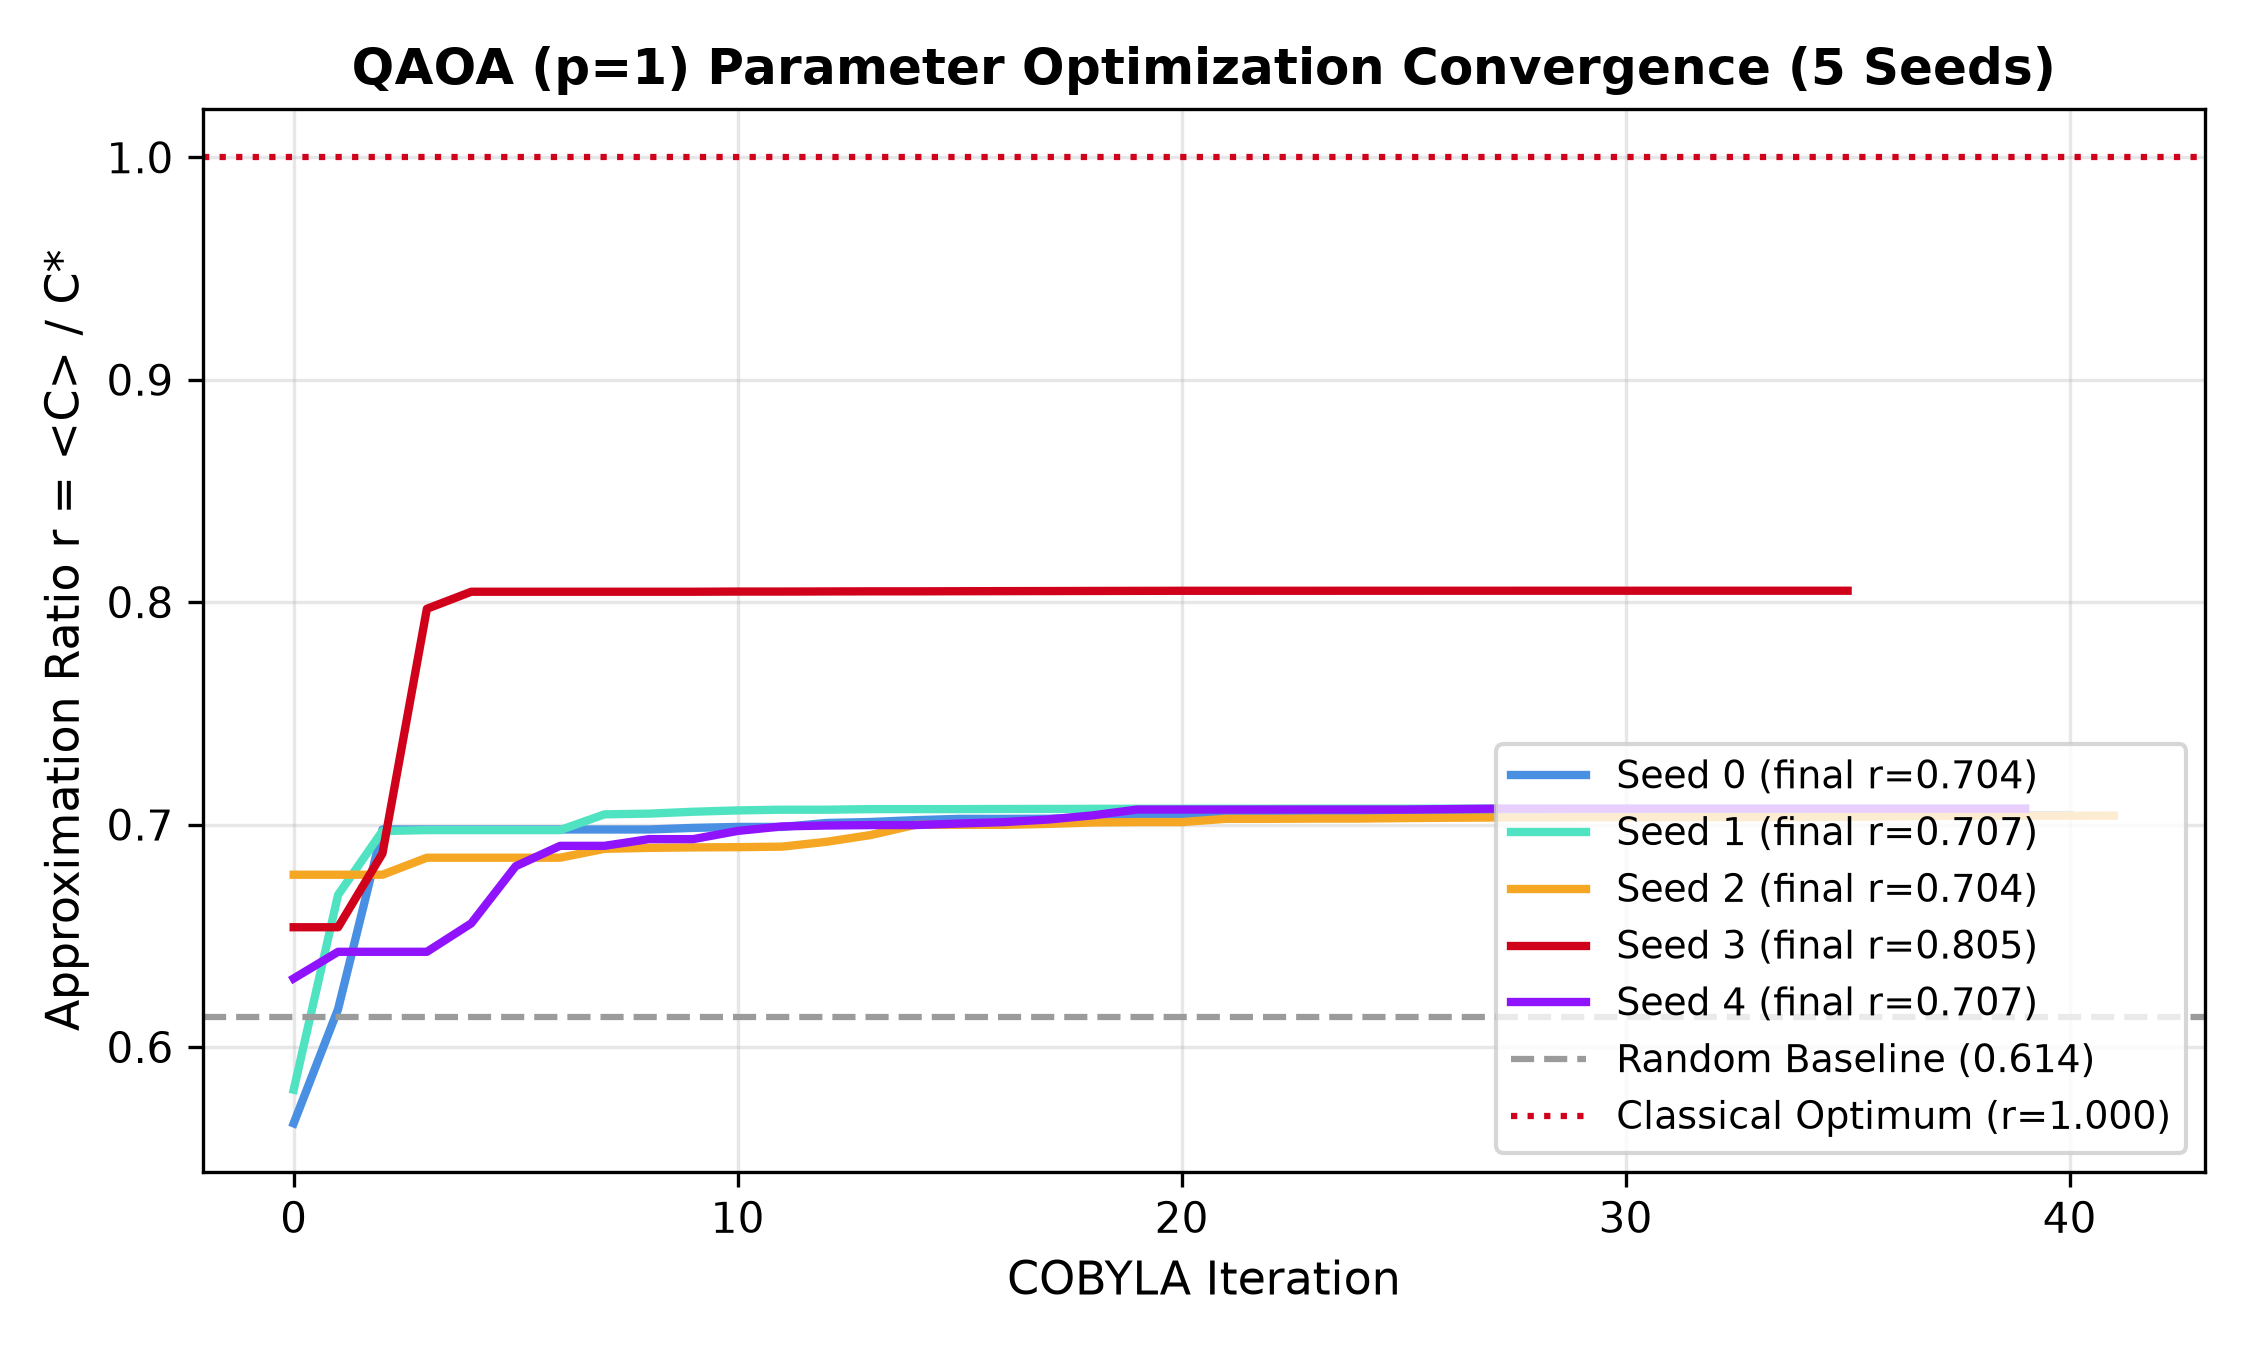

=== Figure: results/figures/cut_distribution.png ===


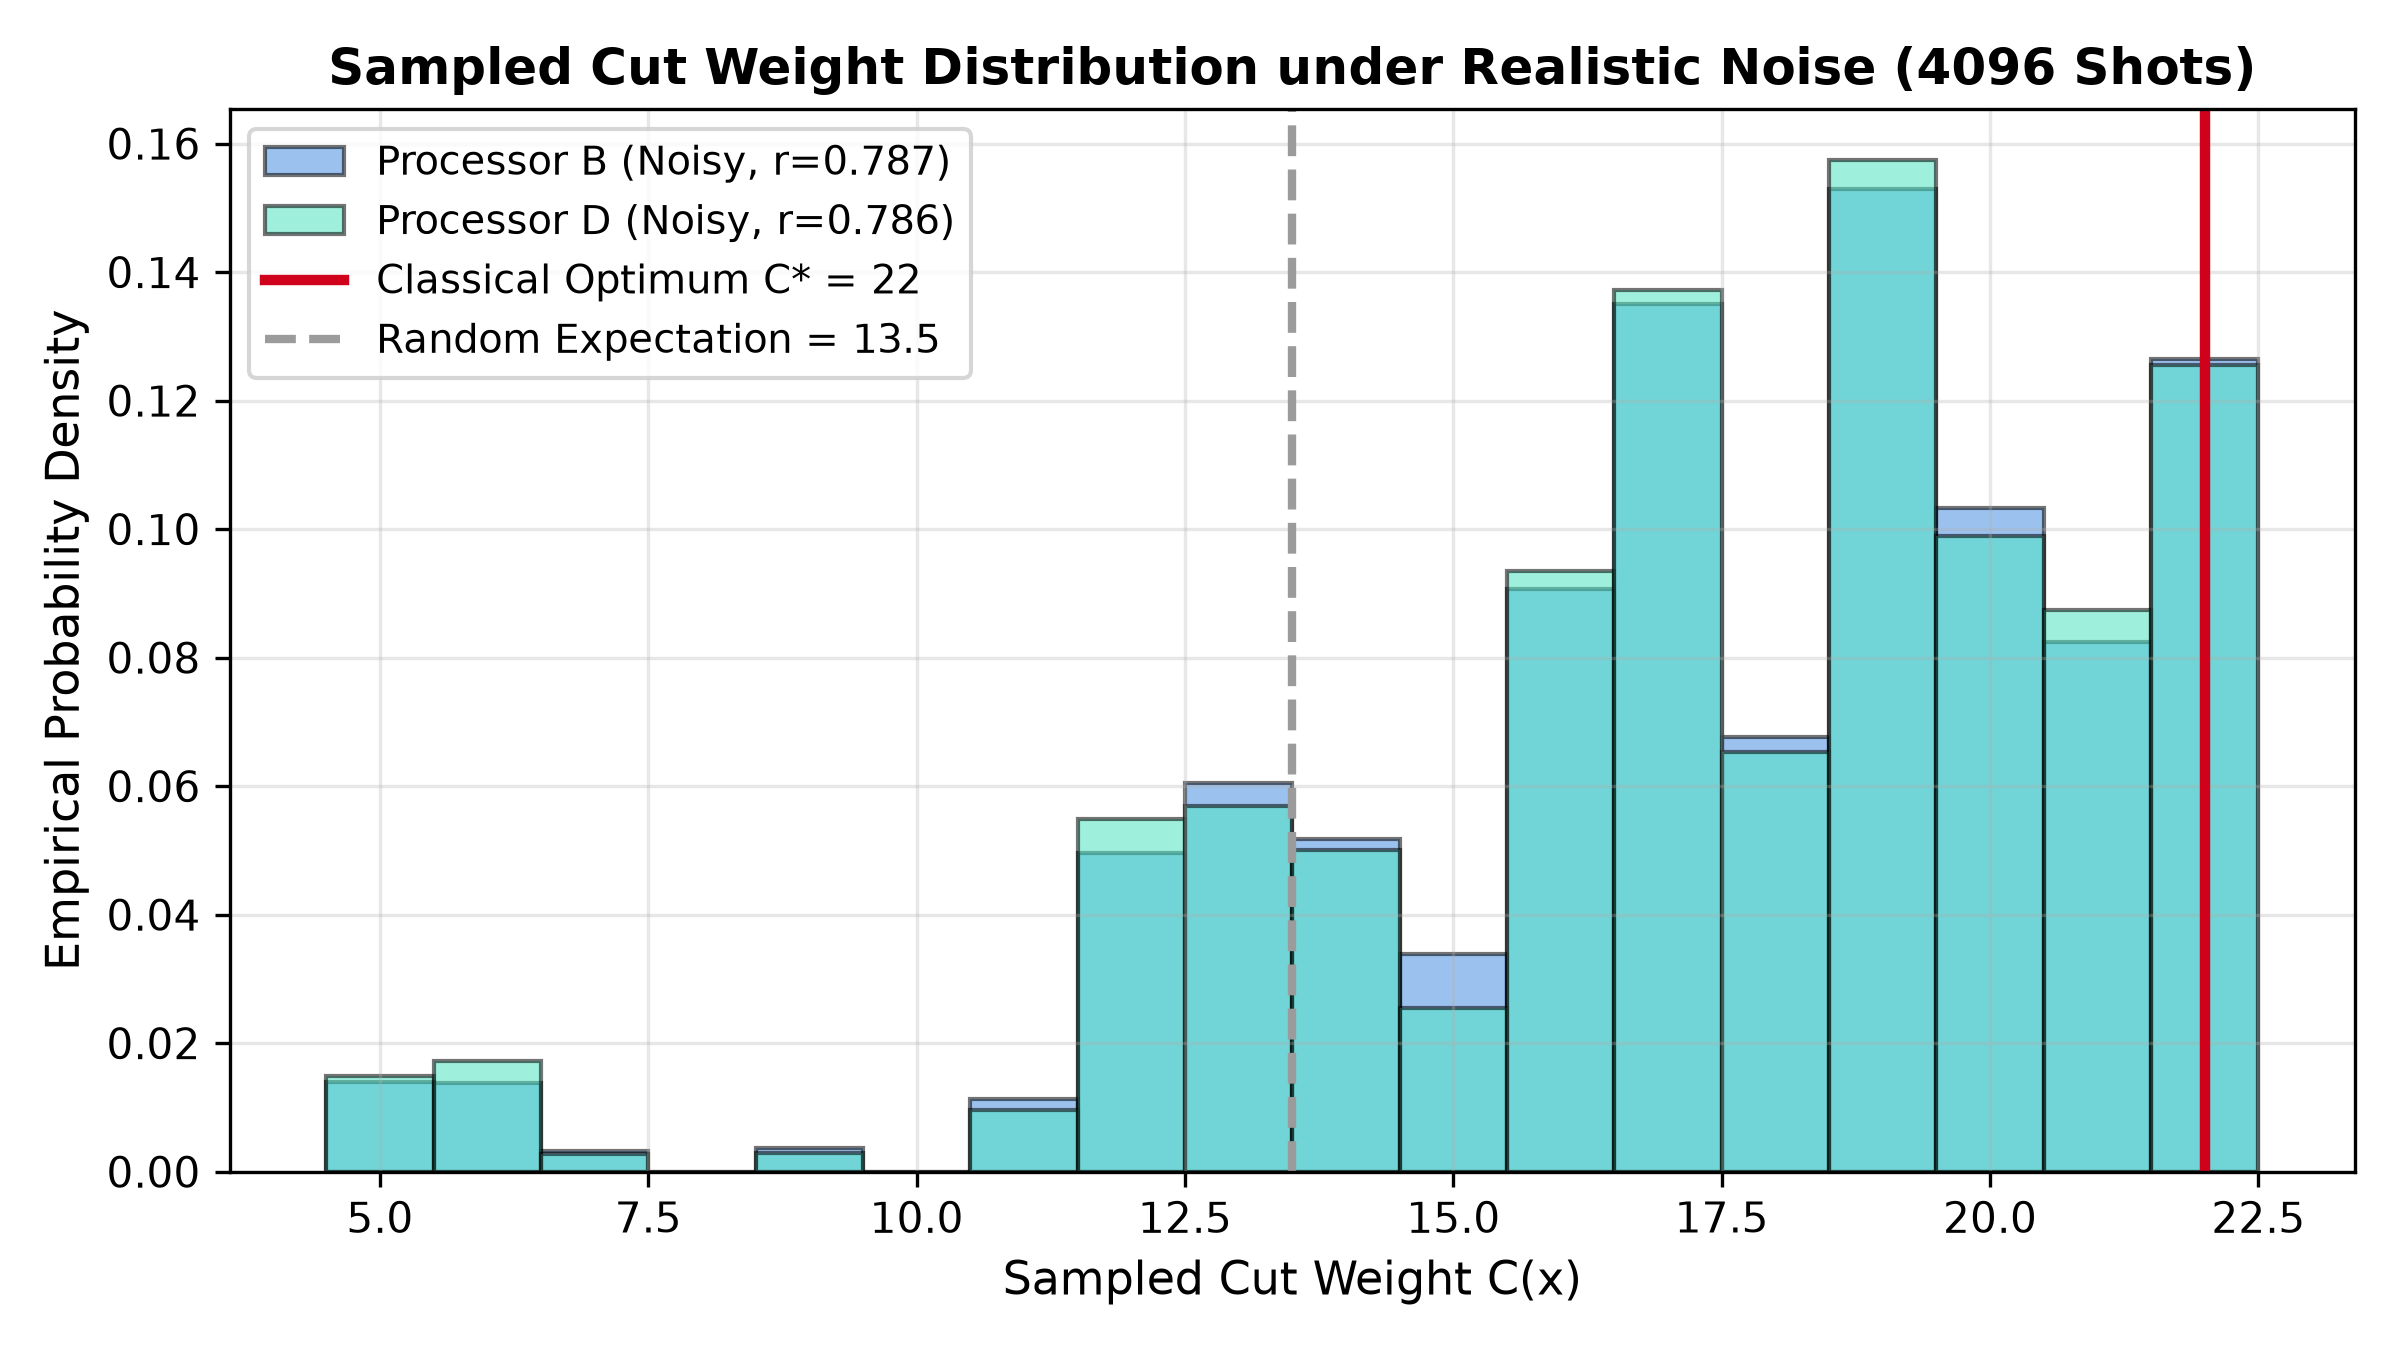

=== Figure: results/figures/bell_fidelity.png ===


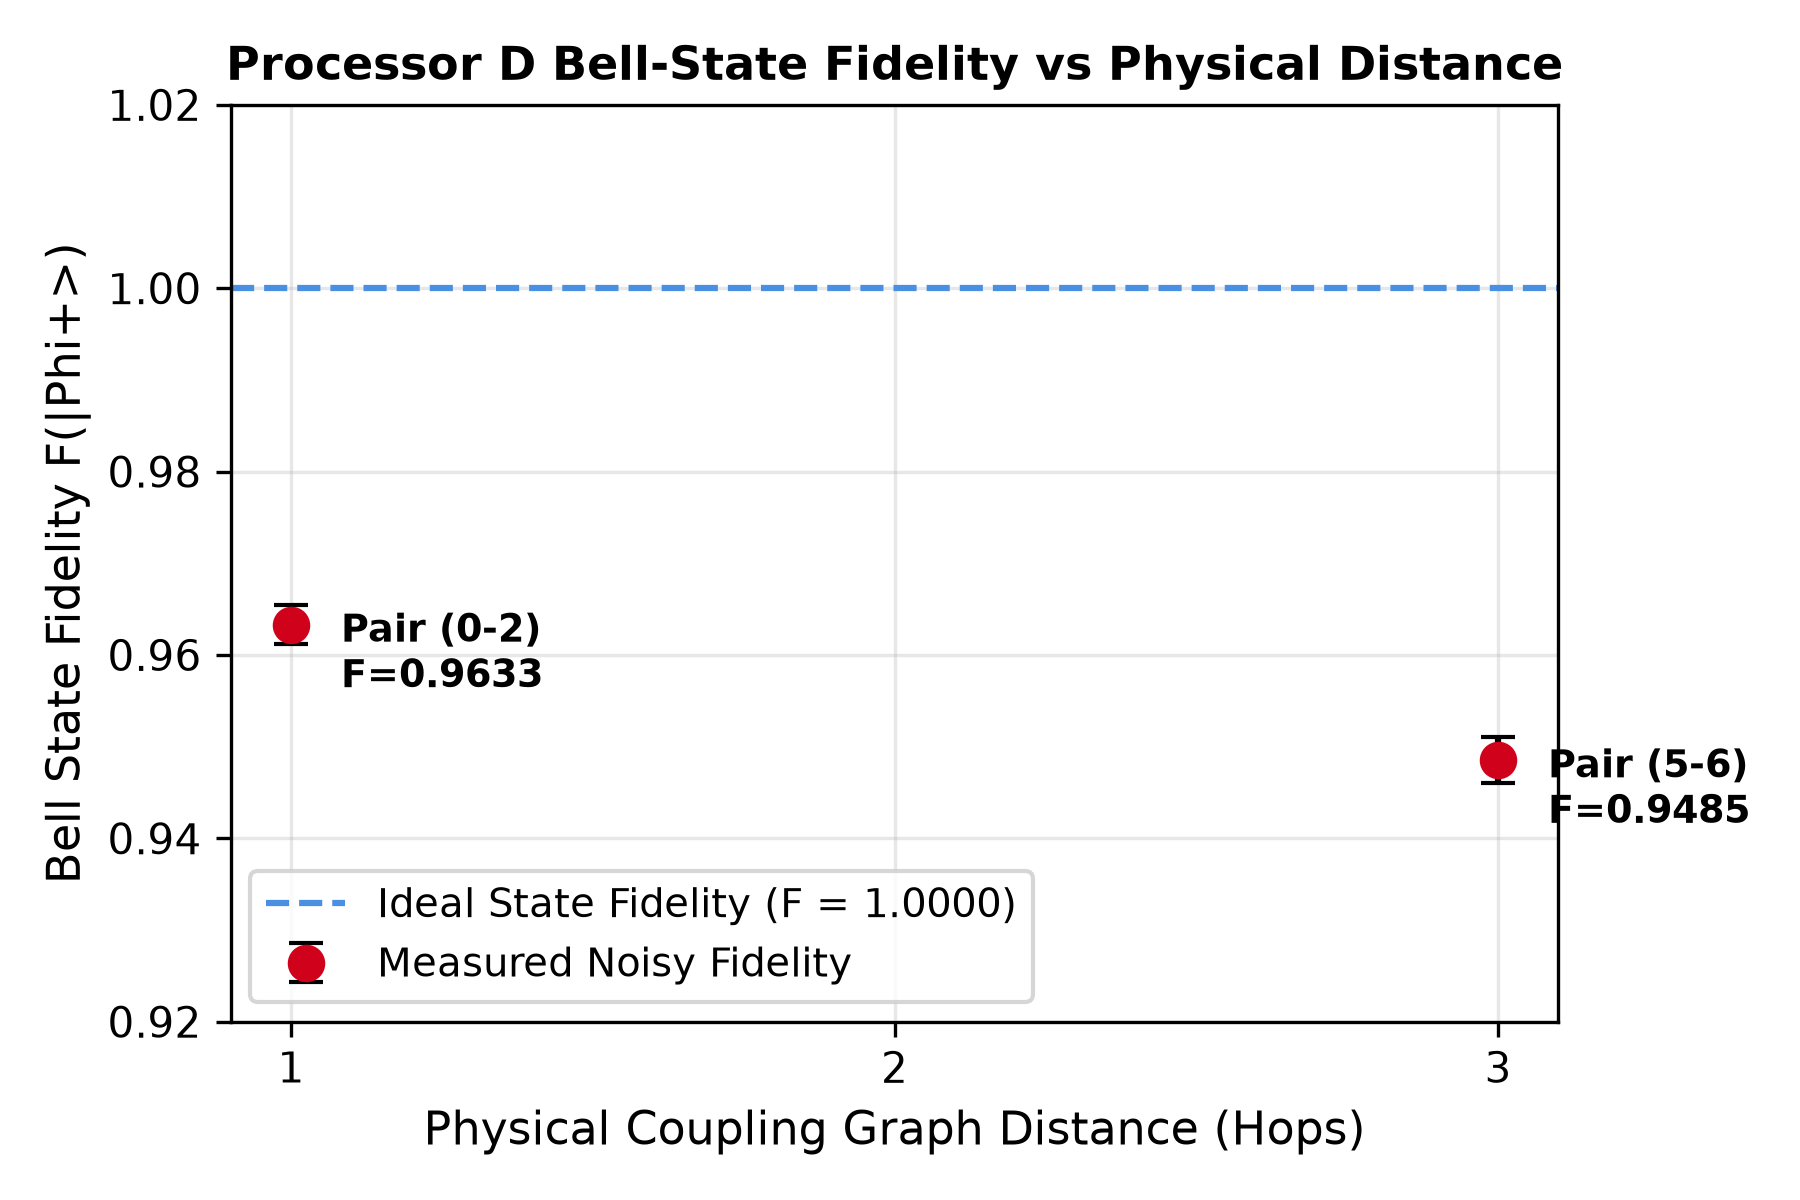

In [9]:
try:
    from IPython.display import Image, display
    has_ipython = True
except ImportError:
    has_ipython = False

figures = [
    "results/figures/problem_graph_partition.png",
    "results/figures/architecture_topologies.png",
    "results/figures/circuit_metrics_comparison.png",
    "results/figures/convergence_curves.png",
    "results/figures/cut_distribution.png",
    "results/figures/bell_fidelity.png"
]

for fig_path in figures:
    if Path(fig_path).exists():
        print(f"=== Figure: {fig_path} ===")
        if has_ipython:
            display(Image(filename=fig_path, width=700))
        else:
            print(f"  [OK] Figure verified: {fig_path}")
